# 07 · Análisis final: ¿Acacías vive del petróleo?

**Pregunta:** entre 2012 y 2026, ¿la producción petrolera y las regalías de Acacías (Meta) se tradujeron en mejores condiciones de vida para sus habitantes?

Este notebook **no limpia datos**: usa las tablas que dejaron los notebooks 01 a 06 en `data processed/` y arma la historia con las gráficas clave. Las gráficas se guardan en `figuras/` para usarlas en el README o en una presentación.

**Fuentes:** ANH (producción y regalías), DNP-SICODIS (regalías recibidas), DNP-MapaInversiones (proyectos), DNP-TerriData (indicadores sociales), Colombia Compra Eficiente-SECOP II (contratos), DANE (IPC). Valores monetarios en **pesos constantes de 2025**.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

DATA = Path("../data processed")
FIG = Path("../figuras")
FIG.mkdir(exist_ok=True)
ANIO_BASE = 2025

# Paleta: un color por entidad, siempre el mismo en todas las gráficas
AZUL, NARANJA, AQUA = "#257de0", "#f47230", "#00b894"
GRIS, TEXTO, TEXTO2, GRILLA = "#b8bec6", "#191919", "#666666", "#e6e6e6"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.edgecolor": GRILLA, "axes.labelcolor": TEXTO2, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlecolor": TEXTO, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRILLA, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": TEXTO2, "ytick.color": TEXTO2, "legend.frameon": False,
})

def fuente(fig, texto):
    fig.text(0.01, -0.02, texto, fontsize=8, color=TEXTO2, ha="left")

def guardar(fig, nombre):
    fig.savefig(FIG / nombre, bbox_inches="tight", facecolor="white")

miles = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))

## 1. Acacías es una potencia petrolera

Acacías es el **segundo municipio productor del Meta**, después de Puerto Gaitán. Sus campos (Chichimene, Castilla, Akacías) producen alrededor de **100.000 barriles diarios**.

Top 5 productores del Meta en 2025 (barriles/día):
     municipio      bpd
 PUERTO GAITAN 202909.0
       ACACIAS  97497.0
CASTILLA NUEVA  58272.0
      CABUYARO  29416.0
        GUAMAL  24528.0


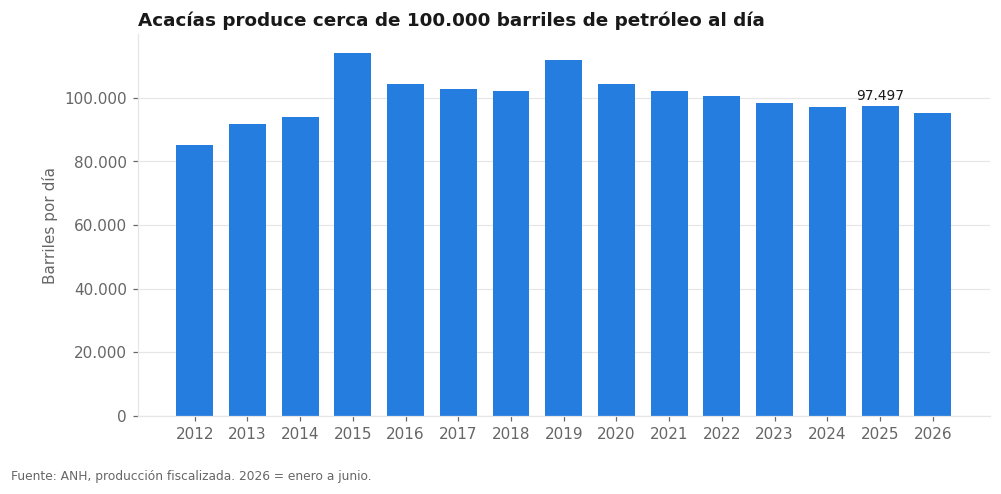

In [2]:
anh = pd.read_csv(DATA / "anh_municipios_anual.csv")
ac = anh[anh["municipio"] == "ACACIAS"].set_index("anio")
ac["bpd"] = ac["petroleo_bls"] / (ac["meses_reportados"] * 365 / 12)

ranking = (anh[anh["anio"] == 2025].nlargest(5, "petroleo_bls")
             .assign(bpd=lambda d: d["petroleo_bls"] / 365)[["municipio", "bpd"]])
print("Top 5 productores del Meta en 2025 (barriles/día):")
print(ranking.round(0).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(ac.index, ac["bpd"], color=AZUL, width=0.7)
ax.yaxis.set_major_formatter(miles)
ax.set_title("Acacías produce cerca de 100.000 barriles de petróleo al día")
ax.set_ylabel("Barriles por día")
ax.set_xticks(ac.index)
ax.tick_params(axis="x", rotation=0)
ax.annotate(f"{ac.loc[2025, 'bpd']:,.0f}".replace(",", "."), (2025, ac.loc[2025, "bpd"]),
            textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9, color=TEXTO)
fuente(fig, "Fuente: ANH, producción fiscalizada. 2026 = enero a junio.")
guardar(fig, "01_produccion_acacias.png")
plt.show()

## 2. Genera mucho, recibe poco

La producción de Acacías genera **cientos de miles de millones de pesos al año en regalías**. Pero, con el Sistema General de Regalías, la mayor parte se reparte entre fondos regionales, el departamento y el ahorro. A la **alcaldía** le llegan solo las **Asignaciones Directas**.

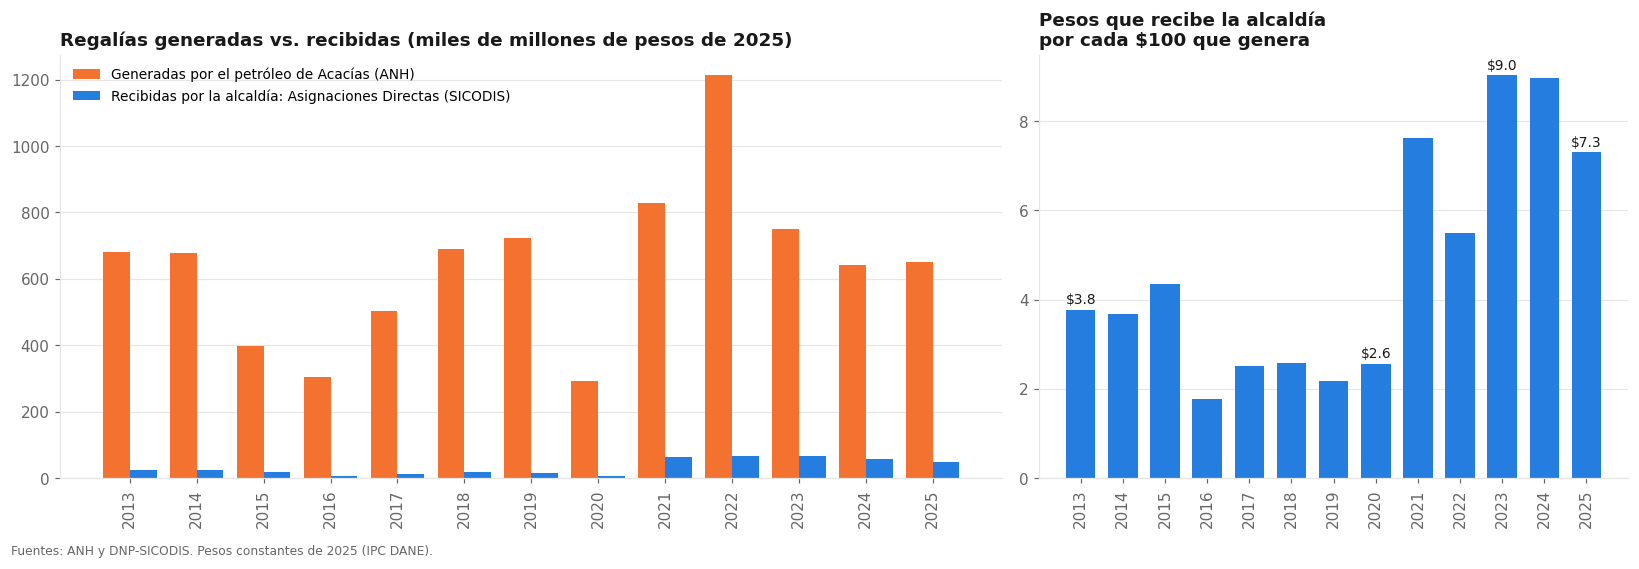

Total 2013-2025: generadas 8,351 mm, recibidas 430 mm -> $5.1 por cada $100


In [3]:
gvr = pd.read_csv(DATA / "acacias_generado_vs_recibido.csv").set_index("anio").loc[2013:2025]
gen = gvr[f"regalias_generadas_anh_const{ANIO_BASE}"] / 1e9
rec = gvr[f"asignaciones_directas_recibidas_const{ANIO_BASE}"] / 1e9
por100 = 100 * rec / gen

fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.6, 1]})
x = gvr.index
ax[0].bar(x - 0.2, gen, width=0.4, color=NARANJA, label="Generadas por el petróleo de Acacías (ANH)")
ax[0].bar(x + 0.2, rec, width=0.4, color=AZUL, label="Recibidas por la alcaldía: Asignaciones Directas (SICODIS)")
ax[0].set_title(f"Regalías generadas vs. recibidas (miles de millones de pesos de {ANIO_BASE})")
ax[0].set_xticks(x)
ax[0].legend(loc="upper left", fontsize=9)

ax[1].bar(x, por100, color=AZUL, width=0.7)
ax[1].set_title("Pesos que recibe la alcaldía\npor cada $100 que genera")
ax[1].set_xticks(x)
ax[1].tick_params(axis="x", rotation=90)
for anio in [2013, 2020, 2023, 2025]:
    ax[1].annotate(f"${por100[anio]:.1f}", (anio, por100[anio]), textcoords="offset points",
                   xytext=(0, 4), ha="center", fontsize=9, color=TEXTO)
ax[0].tick_params(axis="x", rotation=90)
fuente(fig, f"Fuentes: ANH y DNP-SICODIS. Pesos constantes de {ANIO_BASE} (IPC DANE).")
plt.tight_layout()
guardar(fig, "02_generado_vs_recibido.png")
plt.show()

print(f"Total 2013-2025: generadas {gen.sum():,.0f} mm, recibidas {rec.sum():,.0f} mm "
      f"-> ${100 * rec.sum() / gen.sum():.1f} por cada $100")

**Hallazgo:** la alcaldía recibe entre **$2 y $9 por cada $100** de regalías que produce su petróleo. Desde 2021, con el nuevo régimen del SGR (Ley 2056 de 2020), la porción subió, pero sigue siendo menos de una décima parte.

## 3. ¿En qué se invirtió?

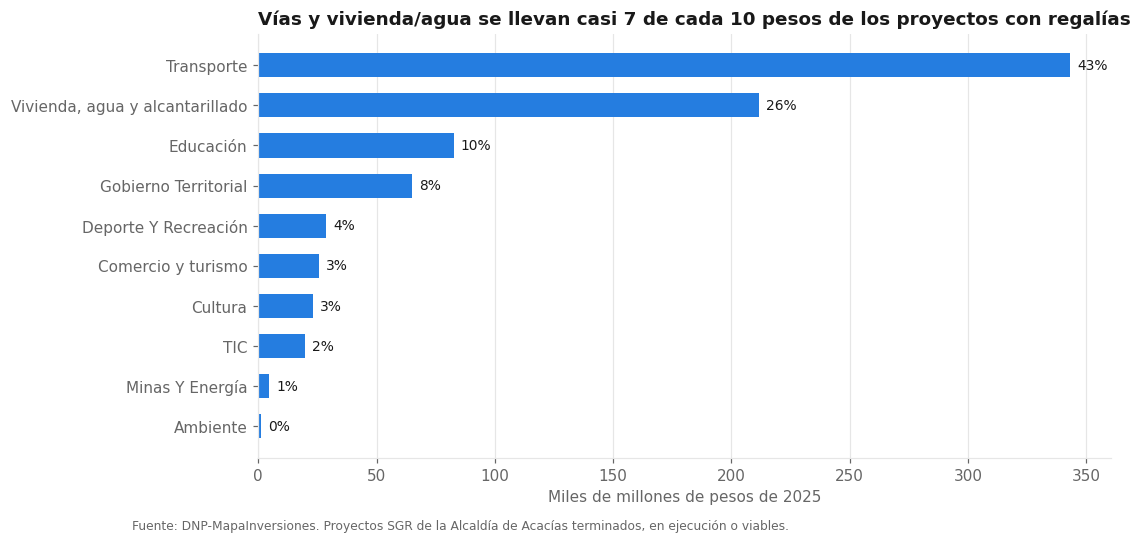

In [4]:
sect = pd.read_csv(DATA / "proyectos_sgr_por_sector.csv").set_index("sector")["valor_mm"].sort_values()
nombres = {"Vivienda, Ciudad Y Territorio": "Vivienda, agua y alcantarillado",
           "Tecnologías De La Información Y Las Comunicaciones": "TIC",
           "Comercio, Industria Y Turismo": "Comercio y turismo",
           "Ambiente Y Desarrollo Sostenible": "Ambiente"}
sect.index = [nombres.get(s, s) for s in sect.index]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(sect.index, sect.values, color=AZUL, height=0.6)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title(f"Vías y vivienda/agua se llevan casi 7 de cada 10 pesos de los proyectos con regalías")
ax.set_xlabel(f"Miles de millones de pesos de {ANIO_BASE}")
pct = 100 * sect / sect.sum()
for i, (v, p) in enumerate(zip(sect.values, pct.values)):
    ax.text(v + 3, i, f"{p:.0f}%", va="center", fontsize=9, color=TEXTO)
fuente(fig, "Fuente: DNP-MapaInversiones. Proyectos SGR de la Alcaldía de Acacías terminados, en ejecución o viables.")
guardar(fig, "03_inversion_por_sector.png")
plt.show()

## 4. ¿Mejoró la vida de la gente?

Comparamos el **último dato disponible** de Acacías con el del Meta y el de Colombia.

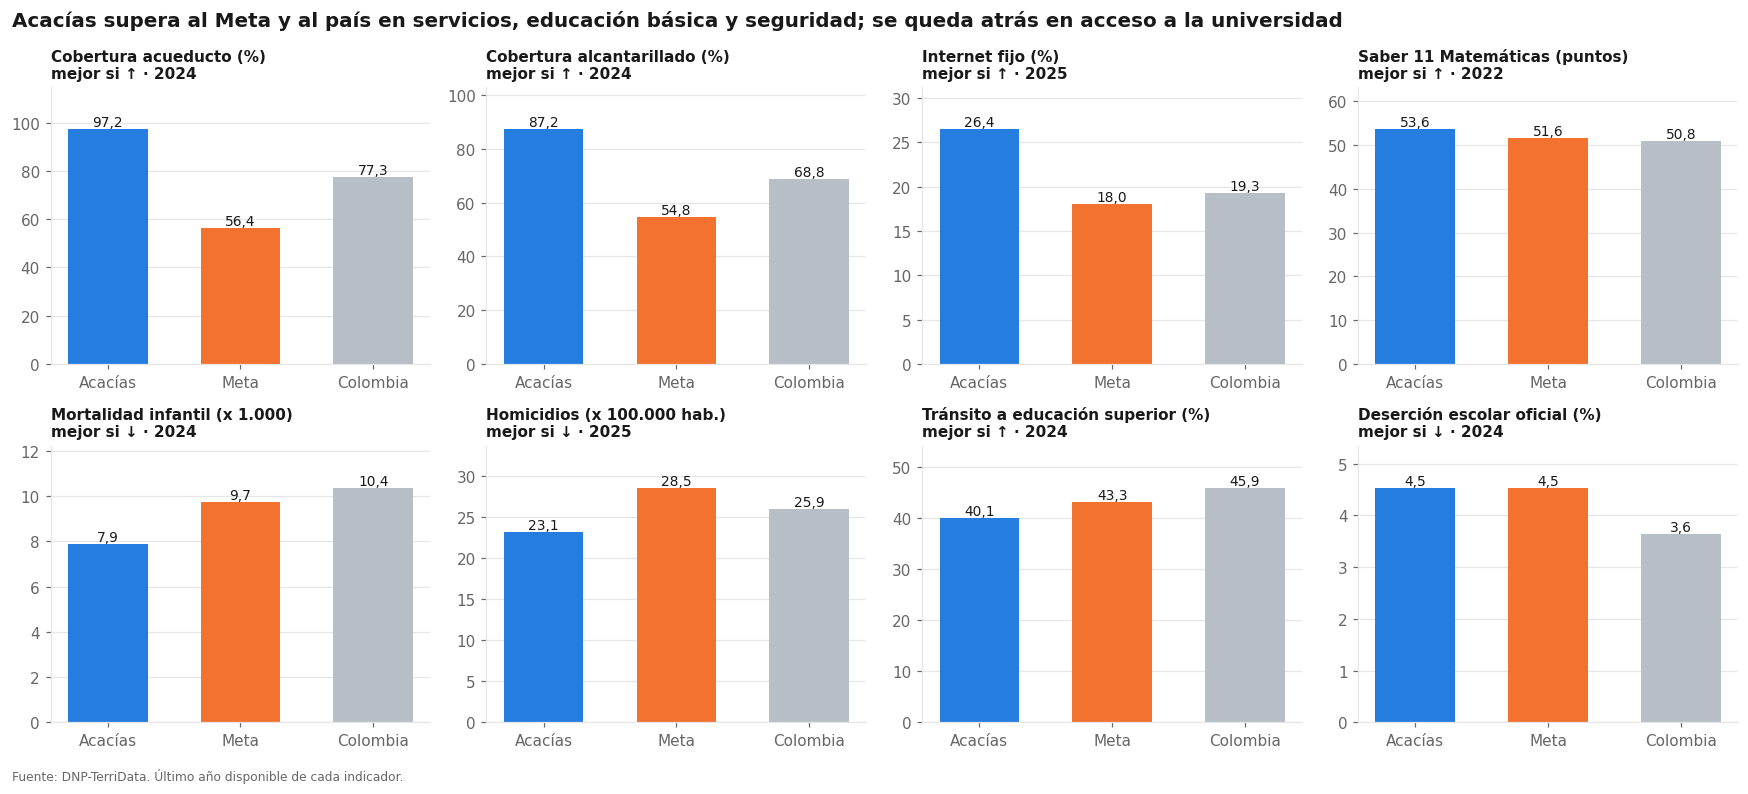

In [5]:
panel = pd.read_csv(DATA / "terridata_panel_indicadores.csv")
elegidos = ["Cobertura acueducto (%)", "Cobertura alcantarillado (%)", "Internet fijo (%)",
            "Saber 11 Matemáticas (puntos)", "Mortalidad infantil (x 1.000)", "Homicidios (x 100.000 hab.)",
            "Tránsito a educación superior (%)", "Deserción escolar oficial (%)"]
lugares = {"Acacías": AZUL, "Meta": NARANJA, "Colombia": GRIS}

ult = (panel[panel["nombre"].isin(elegidos) & panel["lugar"].isin(lugares) & panel["valor"].notna() & (panel["anio"] <= 2025)]
         .sort_values("anio").groupby(["nombre", "lugar"]).last().reset_index())
mejor = panel.drop_duplicates("nombre").set_index("nombre")["mejor"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, nombre in zip(axes.flat, elegidos):
    sub = ult[ult["nombre"] == nombre].set_index("lugar").reindex(list(lugares))
    ax.bar(sub.index, sub["valor"], color=list(lugares.values()), width=0.6)
    for i, v in enumerate(sub["valor"]):
        ax.text(i, v, f"{v:,.1f}".replace(",", "X").replace(".", ",").replace("X", "."),
                ha="center", va="bottom", fontsize=9, color=TEXTO)
    anio = int(sub.loc["Acacías", "anio"])
    flecha = "↑" if mejor[nombre] == "sube" else "↓"
    ax.set_title(f"{nombre}\nmejor si {flecha} · {anio}", fontsize=10)
    ax.set_ylim(0, sub["valor"].max() * 1.18)
fig.suptitle("Acacías supera al Meta y al país en servicios, educación básica y seguridad; se queda atrás en acceso a la universidad",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=TEXTO)
fuente(fig, "Fuente: DNP-TerriData. Último año disponible de cada indicador.")
plt.tight_layout()
guardar(fig, "04_indicadores_sociales.png")
plt.show()

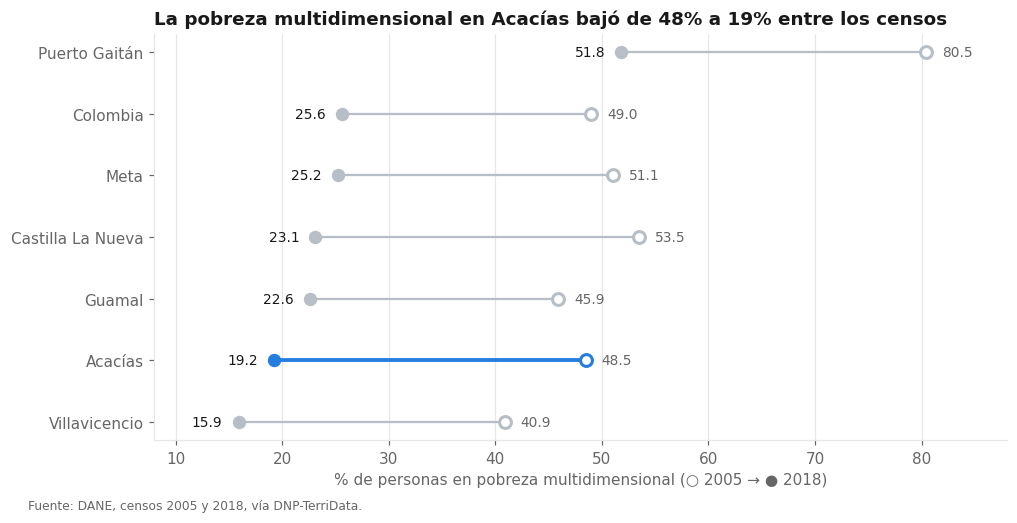

In [6]:
censo = pd.read_csv(DATA / "terridata_pobreza_censos.csv")
ipm = (censo[censo["indicador"] == "indice de pobreza multidimensional - IPM (Censo)"]
         .set_index("lugar")[["2005", "2018"]].astype(float).sort_values("2018"))

fig, ax = plt.subplots(figsize=(10, 4.8))
for i, (lugar, r) in enumerate(ipm.iterrows()):
    color = AZUL if lugar == "Acacías" else GRIS
    ax.plot([r["2005"], r["2018"]], [i, i], color=color, lw=2.5 if lugar == "Acacías" else 1.5, zorder=1)
    ax.scatter(r["2005"], i, s=60, color="white", edgecolor=color, lw=2, zorder=2)
    ax.scatter(r["2018"], i, s=60, color=color, zorder=2)
    ax.text(r["2018"] - 1.5, i, f"{r['2018']:.1f}", ha="right", va="center", fontsize=9, color=TEXTO)
    ax.text(r["2005"] + 1.5, i, f"{r['2005']:.1f}", ha="left", va="center", fontsize=9, color=TEXTO2)
ax.set_yticks(range(len(ipm)))
ax.set_yticklabels(ipm.index)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("% de personas en pobreza multidimensional (○ 2005 → ● 2018)")
ax.set_xlim(8, 88)
ax.set_title("La pobreza multidimensional en Acacías bajó de 48% a 19% entre los censos")
fuente(fig, "Fuente: DANE, censos 2005 y 2018, vía DNP-TerriData.")
guardar(fig, "05_pobreza_censos.png")
plt.show()

## 5. La contratación sigue el calendario electoral

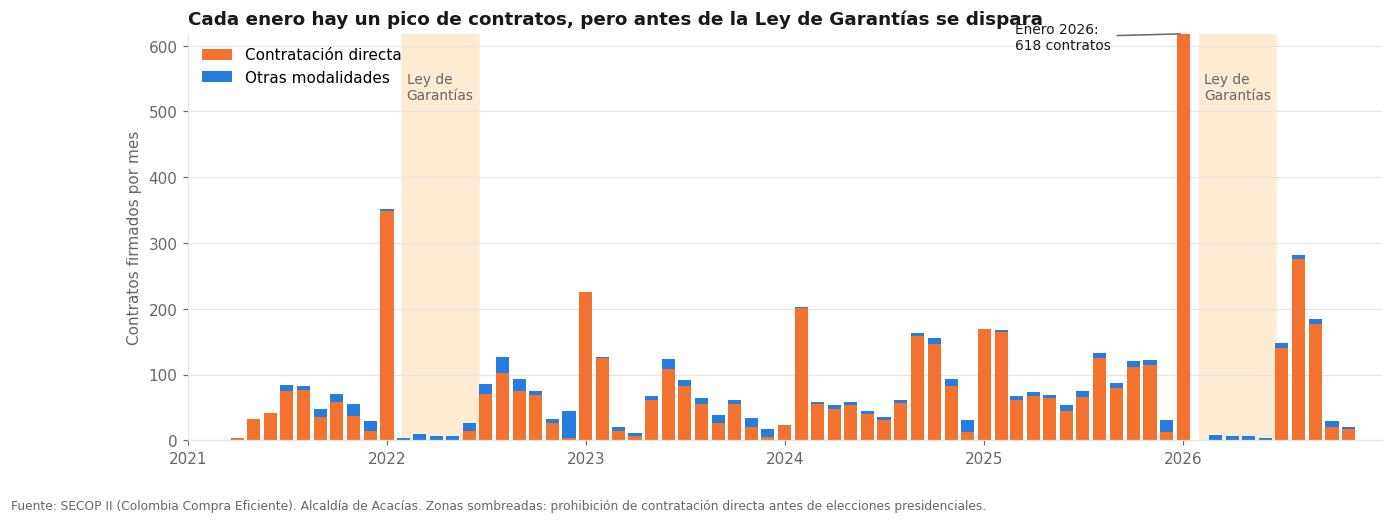

In [7]:
mensual = pd.read_csv(DATA / "secop_alcaldia_mensual.csv", parse_dates=["mes"]).set_index("mes").fillna(0)
directa = mensual.get("Directa", 0)
otras = mensual.drop(columns="Directa", errors="ignore").sum(axis=1)

fig, ax = plt.subplots(figsize=(14, 4.8))
for ini, fin in [("2022-01-29", "2022-06-19"), ("2026-01-31", "2026-06-21")]:
    ax.axvspan(pd.Timestamp(ini), pd.Timestamp(fin), color="#fdebd3", zorder=0)
    ax.text(pd.Timestamp(ini) + pd.Timedelta(days=8), 560, "Ley de\nGarantías", fontsize=9, color=TEXTO2, va="top")
ax.bar(mensual.index, directa, width=24, color=NARANJA, label="Contratación directa")
ax.bar(mensual.index, otras, bottom=directa, width=24, color=AZUL, label="Otras modalidades")
ax.annotate("Enero 2026:\n618 contratos", (pd.Timestamp("2026-01-01"), 618), xytext=(-110, -10),
            textcoords="offset points", fontsize=9, color=TEXTO, arrowprops=dict(arrowstyle="-", color=TEXTO2))
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xlim(pd.Timestamp("2021-01-01"), pd.Timestamp("2026-12-31"))
ax.set_title("Cada enero hay un pico de contratos, pero antes de la Ley de Garantías se dispara")
ax.set_ylabel("Contratos firmados por mes")
ax.legend(loc="upper left")
fuente(fig, "Fuente: SECOP II (Colombia Compra Eficiente). Alcaldía de Acacías. Zonas sombreadas: prohibición de contratación directa antes de elecciones presidenciales.")
guardar(fig, "06_ley_de_garantias.png")
plt.show()

**Ojo con la lectura:** todos los eneros hay un pico, porque al empezar el año fiscal se renuevan los contratos de prestación de servicios. Pero en los años con elecciones presidenciales el pico es mucho mayor: unos 350 contratos en enero de 2022 y **618 en enero de 2026**, frente a unos 200 en enero de 2023 y 2024.

## 6. Conclusiones

1. **Acacías es un gigante petrolero:** produce alrededor de 100.000 barriles diarios, y las actividades primarias son cerca del 80% de su economía.
2. **Pero la alcaldía recibe una fracción pequeña de las regalías que genera:** entre $2 y $9 por cada $100. El resto se reparte en el sistema nacional.
3. **Lo que llega se invierte sobre todo en cemento:** vías, vivienda y acueducto/alcantarillado se llevan casi el 70% de los proyectos con regalías.
4. **Acacías está mejor que el promedio** del Meta y de Colombia en servicios públicos, pruebas Saber, internet y seguridad, y su pobreza multidimensional cayó a menos de la mitad entre 2005 y 2018.
5. **Pero el salto de regalías desde 2021 no se nota claramente en los indicadores**, y el acceso a la educación superior sigue rezagado.
6. **La contratación responde al calendario electoral:** el pico normal de enero se multiplica antes de la Ley de Garantías y una "nómina paralela" de cientos de contratistas que crece cada año.

## Limitaciones

- **Correlación no es causalidad:** que un indicador mejore mientras llegan regalías no prueba que las regalías lo causaron.
- **Regalías "recibidas" = solo Asignaciones Directas.** Acacías también se beneficia de proyectos regionales o departamentales; la inversión de la Gobernación dentro del municipio no se cuantificó.
- **Cambios de metodología** en algunos indicadores (vacunación 2021, mortalidad infantil 2017) impiden leer tendencias largas en ellos.
- **SECOP II cubre la alcaldía solo desde 2021.**
- **Avances físicos en 0%** en MapaInversiones parecen falta de reporte (el cruce con SECOP muestra contratos ejecutados y prorrogados), no obras abandonadas.

## Próximos pasos

- Comparar con municipios **similares sin petróleo** (por ejemplo con *matching*) para estimar el efecto real de las regalías.
- Agregar la inversión de la Gobernación del Meta en Acacías.
- Publicar un **dashboard** interactivo (Power BI o Streamlit) con estas tablas.